# 05 - Newton's method for nonlinear systems: a two-diode network

**Goal.** Solve $F(x) = 0$ for several unknowns, compare an analytic and a finite-difference Jacobian, and test whether damping helps with exponential nonlinearities.

**Problem** A source $V_s = 5$ V feeds node 1 through $R_1 = 1\,\text{k}\Omega$. From node 1, diode $D_2$ goes to ground and diode $D_1$ goes to node 2, which connects to ground through $R_2 = 2\,\text{k}\Omega$. With $i_{D1} = I_s(e^{(v_1 - v_2)/nV_T} - 1)$ and $i_{D2} = I_s(e^{v_1/nV_T} - 1)$, Kirchhoff's current law at the two nodes gives

$$F_1 = \frac{v_1 - V_s}{R_1} + i_{D1} + i_{D2} = 0, \qquad F_2 = \frac{v_2}{R_2} - i_{D1} = 0.$$

In [1]:
import sys
sys.path.insert(0, "../src")  # lets this notebook run without installing the package

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (6.5, 3.6), "axes.grid": True})
from scipy.optimize import brentq, root

from nummeth import fd_jacobian, newton_system

In [2]:
VS, R1, R2, IS, NVT = 5.0, 1000.0, 2000.0, 1e-12, 0.02585

def F(v):
    v1, v2 = v
    i_d1 = IS * np.expm1((v1 - v2) / NVT)
    i_d2 = IS * np.expm1(v1 / NVT)
    return np.array([(v1 - VS) / R1 + i_d1 + i_d2,
                     v2 / R2 - i_d1])

def J(v):
    v1, v2 = v
    g = IS / NVT
    e1, e2 = np.exp((v1 - v2) / NVT), np.exp(v1 / NVT)
    return np.array([[1 / R1 + g * e1 + g * e2, -g * e1],
                     [-g * e1, 1 / R2 + g * e1]])

x0 = [0.5, 0.0]
analytic = newton_system(F, x0, jac=J, tol=1e-12)
numeric = newton_system(F, x0, tol=1e-12)

print(f"analytic Jacobian : v = {analytic.x}, iterations = {analytic.iterations}, converged = {analytic.converged}")
print(f"finite differences: v = {numeric.x}, iterations = {numeric.iterations}, converged = {numeric.converged}")
print("max |J_analytic - J_fd| at the solution:", np.max(np.abs(J(analytic.x) - fd_jacobian(F, analytic.x))))

analytic Jacobian : v = [0.5738186  0.11251396], iterations = 7, converged = True
finite differences: v = [0.5738186  0.11251396], iterations = 7, converged = True
max |J_analytic - J_fd| at the solution: 4.4729053794156926e-11


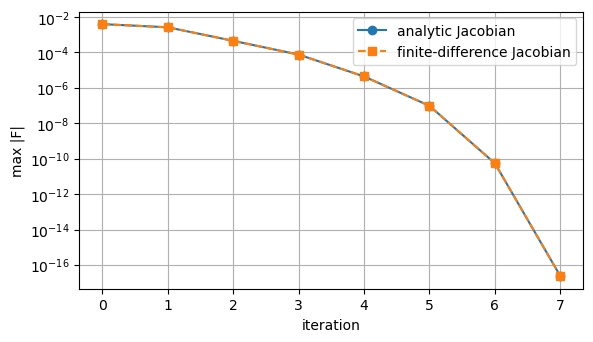

In [3]:
plt.semilogy(analytic.residual_history, "o-", label="analytic Jacobian")
plt.semilogy(numeric.residual_history, "s--", label="finite-difference Jacobian")
plt.xlabel("iteration"); plt.ylabel("max |F|"); plt.legend(); plt.show()

## Independent check

Eliminate $v_2$ with an inner scalar root-find, then solve for $v_1$ with an outer one. This uses a different method entirely, so agreement is meaningful.

In [4]:
def v2_of(v1):
    return brentq(lambda v2: v2 / R2 - IS * np.expm1((v1 - v2) / NVT), -1.0, v1, xtol=1e-15)

v1_ref = brentq(lambda v1: F([v1, v2_of(v1)])[0], 0.1, 1.0, xtol=1e-15)
print("nested brentq reference:", v1_ref, v2_of(v1_ref))
print("difference from my Newton solution:", np.max(np.abs(analytic.x - [v1_ref, v2_of(v1_ref)])))

for method in ("hybr", "lm"):
    sol = root(F, x0, method=method)
    print(f"scipy root, method={method!r}: success = {sol.success}, x = {sol.x}")

nested brentq reference: 0.5738185986082601 0.11251395720640285
difference from my Newton solution: 6.827871601444713e-15
scipy root, method='hybr': success = False, x = [0.5 0. ]
scipy root, method='lm': success = True, x = [0.5738186  0.11251396]


## Damping

Newton's method can overshoot when it starts far from the solution. A backtracking line search halves the step until the residual decreases. Compare damped and undamped runs from several starting points. The last start is deliberately extreme.

In [5]:
starts = [[0.5, 0.0], [0.0, 0.0], [0.2, 0.0], [2.0, 1.0], [3.0, 0.0], [1.0, -1.0]]
print(f"{'start':<14}{'damped':<38}{'undamped'}")
for x_start in starts:
    cols = []
    for damping in (True, False):
        r = newton_system(F, x_start, jac=J, damping=damping, max_iter=300)
        cols.append(f"converged={r.converged!s:5} iterations={r.iterations:>3}")
    print(f"{str(x_start):<14}{cols[0]:<38}{cols[1]}")

start         damped                                undamped
[0.5, 0.0]    converged=True  iterations=  6        converged=True  iterations= 17
[0.0, 0.0]    converged=True  iterations=  7        converged=True  iterations=180
[0.2, 0.0]    converged=True  iterations=  7        converged=True  iterations=180
[2.0, 1.0]    converged=True  iterations= 59        converged=True  iterations= 59
[3.0, 0.0]    converged=True  iterations=102        converged=True  iterations=102
[1.0, -1.0]   converged=False iterations=  0        converged=False iterations=  0


In [ ]:
# The failing start [1, -1]: print the Jacobian and the exponential
print(J([1.0, -1.0]))
print("exp((v1 - v2)/nVt) =", np.exp((1.0 + 1.0) / NVT))

[[ 1.54404484e+23 -1.54404484e+23]
 [-1.54404484e+23  1.54404484e+23]]
exp((v1 - v2)/nVt) = 3.991355920065889e+33


In [ ]:
# Why did SciPy's hybr stop? Print each method's own message.
for method in ("hybr", "lm"):
    sol = root(F, x0, method=method)
    print(method, "->", sol.message)

## Observations

- How many iterations did the analytic and finite-difference Jacobians need? What does that say about the cost of an analytic Jacobian?
- SciPy's `hybr` and `lm` methods behaved differently from the same start. What did you observe, and what might explain it?
- From which starting points did damping help, and from which did it make no difference? Explain using the shape of the exponential.
- The last start fails with both settings. Print the Jacobian there and explain what you see.

Both the analytic and the finite-difference Jacobian needed 7 iterations and reached the same solution (the two Jacobians differ by about 4.5e-11 at the solution). The cost difference is per iteration: a central-difference Jacobian needs 2n extra evaluations of F (4 for this two-unknown system), while the analytic Jacobian needs none but must be derived by hand, which is error-prone. For a small system the difference is negligible; for a large system the analytic Jacobian saves many evaluations.

SciPy's `lm` converged from the initial point and `hybr` did not: `hybr` stopped with the message that the iteration was not making good progress (printed in the new cell). Both methods are trust-region style methods, so I cannot say from this alone why `hybr` stopped. The likely suspect is poor scaling: the unknowns are in volts, the residuals are in milliamps, and the exponential terms span many orders of magnitude. I did not confirm this.

Damping helped from starts on the left of the solution ([0, 0], [0.2, 0] and [0.5, 0]). There the exponential is nearly flat, so the Jacobian is small and the full Newton step jumps far to the right, to about v1 = 5 V, where the exponential is huge. Undamped Newton then needs about 180 iterations to crawl back, because on an exponential each step only moves about nVt (about 26 mV). Damping rejects the oversized step, which brought the count down from 180 to 7. From starts on the right ([2, 1] and [3, 0]) the exponential is already steep and convex, so the Newton steps already move steadily toward the root and damping changes nothing (59 and 102 iterations either way).

The extreme start [1, -1] fails at iteration 0 with both settings. It is not an overflow: exp((v1 - v2)/nVt) is about 4e33, far below the float limit of about 1.8e308. The printed Jacobian is [[1.5e23, -1.5e23], [-1.5e23, 1.5e23]]: the small resistor terms (about 1e-3) are lost next to 1e23 in floating point, so the two rows are exactly opposite and the matrix is numerically singular. The linear solve cannot produce a Newton step, so the solver stops immediately.